# Temporal Figures (Figure 3 and Figure S1)

Regenerates the two temporal figures directly from the repository data so that every plotted date and value can be reproduced.

1. **Figure 3** (Section 4.2): daily interaction events (replies, quote tweets, mentions) per narrative for Parliament & Protest, State Apparatus Violence, Affan Kurniawan and Economic Grievance. Dashed lines mark the days referenced in Section 4.2.
2. **Figure S1** (Supplementary Material): daily tweet volume of the twelve largest BERTopic topics before consolidation into narratives, with the August 26 to 30 transition zone shaded.

Inputs (repository paths): `derived-data/hashed/temporal_edges_with_community_hashed.csv` (21,420 interaction events) and `derived-data/hashed/Data_bert_with_topics_hashed.csv` (29,289 tweets). Topic numbers follow the `topic` column, which matches Table S8 (the `topic_label` text is offset by one and is not used).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.colors import LogNorm
import os
OUT = os.environ.get('FIG_OUT', '.')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})

ev = pd.read_csv('temporal_edges_with_community_hashed.csv')   # derived-data/hashed/
ev['day'] = pd.to_datetime(ev['date_day'])
tw = pd.read_csv('Data_bert_with_topics_hashed.csv', sep=None, engine='python')   # derived-data/hashed/
tw['day'] = pd.to_datetime(tw['date'], format='mixed', dayfirst=True).dt.normalize()
days = pd.date_range('2025-08-01', '2025-09-29', freq='D')
print('events', len(ev), '| tweets', len(tw), '| tweet date range', tw.day.min().date(), '->', tw.day.max().date())
tot = tw.groupby('day').size()
print('peak tweet day:', tot.idxmax().date(), int(tot.max()))

events 21420 | tweets 29289 | tweet date range 2025-08-01 -> 2025-09-29
peak tweet day: 2025-08-30 6937


## Figure 3: daily interaction events per narrative

Demo & DPR         marked day 2025-08-25  events 269
Kekerasan Aparat   marked day 2025-08-28  events 512
Affan Kurniawan    marked day 2025-08-31  events 163
Demo & DPR overall max: 2025-08-02 352
Ekonomi Rakyat overall max: 2025-08-30 452


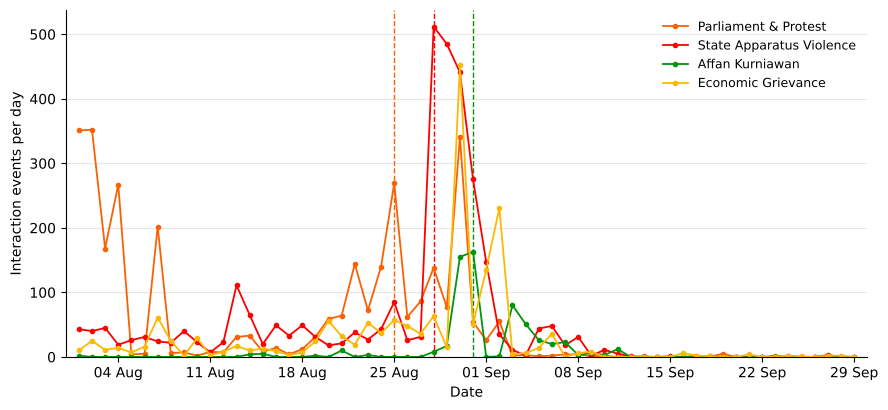

In [2]:
NARR = [('Demo & DPR', 'Parliament & Protest', '#FA6103'),
        ('Kekerasan Aparat', 'State Apparatus Violence', '#FF0000'),
        ('Affan Kurniawan', 'Affan Kurniawan', '#00960B'),
        ('Ekonomi Rakyat', 'Economic Grievance', '#FDB805')]
daily = ev.groupby(['day', 'narrative']).size().unstack(fill_value=0).reindex(days, fill_value=0)

# days referenced in Section 4.2
marks = {'Demo & DPR': daily.loc['2025-08-20':'2025-08-26', 'Demo & DPR'].idxmax(),   # late pre-shift peak
         'Kekerasan Aparat': daily['Kekerasan Aparat'].idxmax(),
         'Affan Kurniawan': daily['Affan Kurniawan'].idxmax()}
for k, d in marks.items():
    print(f'{k:18} marked day {d.date()}  events {int(daily.loc[d, k])}')
print('Demo & DPR overall max:', daily['Demo & DPR'].idxmax().date(), int(daily['Demo & DPR'].max()))
print('Ekonomi Rakyat overall max:', daily['Ekonomi Rakyat'].idxmax().date(), int(daily['Ekonomi Rakyat'].max()))

fig, ax = plt.subplots(figsize=(9, 4.2))
for key, label, col in NARR:
    ax.plot(daily.index, daily[key], marker='o', ms=3, lw=1.3, color=col, label=label)
COL = {k: c for k, _, c in NARR}
# dashed lines at the days referenced in Section 4.2 (dates are given in the caption)
for key, d in marks.items():
    ax.axvline(d, color=COL[key], ls='--', lw=1, zorder=1)
ax.set_ylabel('Interaction events per day')
ax.set_xlabel('Date')
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.set_xlim(days[0] - pd.Timedelta(days=1), days[-1] + pd.Timedelta(days=1))
ax.set_ylim(bottom=0)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc='upper right')
fig.tight_layout()
fig.savefig(f'{OUT}/Figure3.png', dpi=300)
plt.show()

## Figure S1: daily volume of the twelve largest topics

top-12 topics: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
each top topic peaks on: {0: '2025-08-30', 1: '2025-08-30', 2: '2025-08-30', 3: '2025-08-30', 4: '2025-08-30', 5: '2025-08-31', 6: '2025-08-29', 7: '2025-08-29', 8: '2025-08-23', 9: '2025-08-30', 10: '2025-08-31', 11: '2025-08-30'}


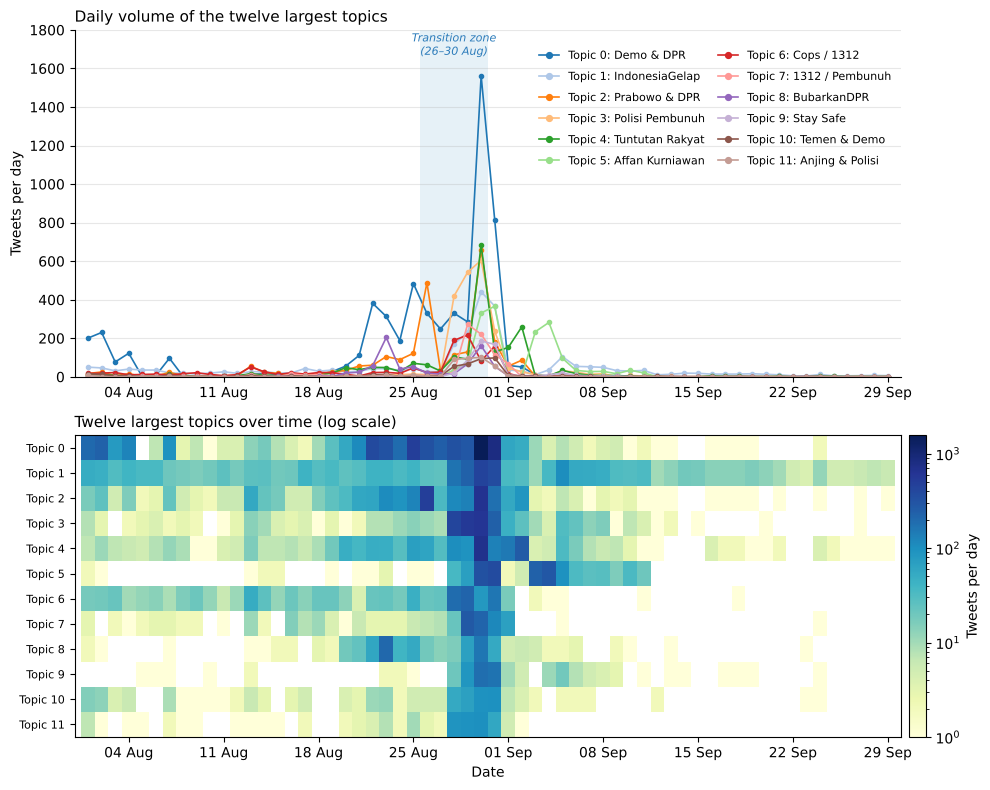

In [3]:
LAB = {0: 'demo, dpr', 1: 'indonesiagelap, resetindonesia', 2: 'prabowo, dpr', 3: 'polisi, polisipembunuh',
       4: 'rakyat, tuntutan', 5: 'affan, kurniawan', 6: 'cops, 1312', 7: '1312, pembunuh',
       8: 'bubarkandprsontoloyo', 9: 'stay, safe', 10: 'temen, demo', 11: 'anjing, polisi',
       12: 'demo, 1312', 13: '1312, medis', 14: 'adilijokowi, indonesiagelap', 15: 'stopbayarpajak, bubarkandpr',
       16: '80, indonesia', 17: 'bendera, takut', 18: 'damai, indonesiaku'}
tt = tw[tw['topic'] >= 0]
top = tt['topic'].value_counts().head(12).index.tolist()
tdaily = tt[tt.topic.isin(top)].groupby(['day', 'topic']).size().unstack(fill_value=0).reindex(days, fill_value=0)[top]
print('top-12 topics:', top)
print('each top topic peaks on:', {t: str(tdaily[t].idxmax().date()) for t in top})

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 8), gridspec_kw={'height_ratios': [1.15, 1]})
NAME = {0: 'Demo & DPR', 1: 'IndonesiaGelap', 2: 'Prabowo & DPR', 3: 'Polisi Pembunuh', 4: 'Tuntutan Rakyat',
        5: 'Affan Kurniawan', 6: 'Cops / 1312', 7: '1312 / Pembunuh', 8: 'BubarkanDPR', 9: 'Stay Safe',
        10: 'Temen & Demo', 11: 'Anjing & Polisi'}   # short names from the Table S8 keywords
z0, z1 = pd.Timestamp('2025-08-26') - pd.Timedelta(hours=12), pd.Timestamp('2025-08-30') + pd.Timedelta(hours=12)
a1.axvspan(z0, z1, color='#9ecae1', alpha=0.25, lw=0)
a1.text(z0 + (z1 - z0) / 2, 1790, 'Transition zone\n(26–30 Aug)', ha='center', va='top', fontsize=8, style='italic', color='#2b7bba')
cmap = plt.get_cmap('tab20')
for i, t in enumerate(top):
    a1.plot(tdaily.index, tdaily[t], marker='o', ms=3, lw=1.2, color=cmap(i), label=f'Topic {t}: {NAME[t]}')
a1.set_ylabel('Tweets per day')
a1.set_title('Daily volume of the twelve largest topics', loc='left', fontsize=11)
a1.legend(ncol=2, fontsize=8, frameon=False, loc='upper right', bbox_to_anchor=(1.0, 0.97),
           handlelength=1.8, markerscale=1.4, labelspacing=0.9, columnspacing=1.2)
a1.set_ylim(0, 1800)
a1.grid(axis='y', alpha=0.3)
a1.spines[['top', 'right']].set_visible(False)
for a in (a1,):
    a.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    a.set_xlim(days[0] - pd.Timedelta(days=1), days[-1] + pd.Timedelta(days=1))

H = tdaily.T.values.astype(float)
im = a2.imshow(np.where(H > 0, H, np.nan), aspect='auto', cmap='YlGnBu', norm=LogNorm(vmin=1, vmax=H.max()),
               extent=[mdates.date2num(days[0] - pd.Timedelta(hours=12)), mdates.date2num(days[-1] + pd.Timedelta(hours=12)), len(top) - 0.5, -0.5])
a2.set_yticks(range(len(top)))
a2.set_yticklabels([f'Topic {t}' for t in top], fontsize=8)
a2.xaxis_date()
a2.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
a2.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
a2.set_xlim(a1.get_xlim())
a2.set_title('Twelve largest topics over time (log scale)', loc='left', fontsize=11)
a2.set_xlabel('Date')
from mpl_toolkits.axes_grid1 import make_axes_locatable
cax = make_axes_locatable(a2).append_axes('right', size='2%', pad=0.08)
fig.colorbar(im, cax=cax, label='Tweets per day')
d1 = make_axes_locatable(a1).append_axes('right', size='2%', pad=0.08); d1.set_visible(False)
fig.tight_layout()
fig.savefig(f'{OUT}/FigureS1.png', dpi=300)
plt.show()